# Examen Parcial - Informe 02 - Redes Neuronales Aprendizaje Profundo - Grupo 07
---
**Crisanto Palacios, Eduardo;**
**Riveros Ruiz, Jason Wilmer;**
**Torres Vela, Juan Carlos (Representante);**
**Zavala Suyo, Rafael**

---
**Prof. Dr.    Aldo Camargo**

---
# 01 · Datos Sen1Floods11: descarga, exploración y calidad de etiquetas

**Proyecto:** Mapeo de inundaciones con Sentinel-1 (SAR) y U-Net · Lima, marzo 2017 (Copernicus EMS EMSN038)


**Convenciones de Sen1Floods11**: S1 con 2 bandas (VV, VH) en dB; etiquetas `1 = agua`, `0 = no agua`, `-1 = sin dato`.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
BASE = '/content/drive/MyDrive/Dagua'
for d in ['code', 'checkpoints', 'results', 'peru']:
    os.makedirs(f'{BASE}/{d}', exist_ok=True)
!pip -q install rasterio
import torch
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NO HAY GPU (Entorno de ejecución > Cambiar tipo > GPU)')

Mounted at /content/drive
GPU: NO HAY GPU (Entorno de ejecución > Cambiar tipo > GPU)


## 1. Utilidades compartidas
La celda siguiente guarda `flood_utils.py` (dataset, U-Net, Attention U-Net, pérdida enmascarada BCE+Dice, métricas IoU/omisión/comisión, bucle de entrenamiento).

In [ ]:
%%writefile /content/drive/MyDrive/Dagua/code/flood_utils.py
"""Utilidades compartidas: datos Sen1Floods11, U-Net / Attention U-Net, pérdidas y métricas."""
import os, json, time, random, subprocess
import numpy as np
import pandas as pd
import rasterio
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

LOCAL = '/content/sen1floods11'
GCS = 'gs://sen1floods11/v1.1'


def set_seed(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def sh(cmd):
    print('$', cmd)
    subprocess.run(cmd, shell=True, check=True)


def chip_id(name):
    return name.split('_S1')[0]


def country(name):
    return name.split('_')[0]


# ----------------------------------------------------------------------------- datos
def download_sen1floods11(n_weak=2000, seed=0, local=LOCAL):
    """Descarga HandLabeled completo (+ splits) y una muestra de n_weak chips débiles (None = todos)."""
    hl = f'{local}/HandLabeled'
    for d in ['S1Hand', 'LabelHand', 'S1OtsuLabelHand']:
        os.makedirs(f'{hl}/{d}', exist_ok=True)
        sh(f'gsutil -m -q rsync -r {GCS}/data/flood_events/HandLabeled/{d} {hl}/{d}')
    os.makedirs(f'{local}/splits', exist_ok=True)
    sh(f'gsutil -m -q cp -r {GCS}/splits/flood_handlabeled {local}/splits/')
    wk = f'{local}/WeaklyLabeled'
    os.makedirs(f'{wk}/S1Weak', exist_ok=True)
    os.makedirs(f'{wk}/S1OtsuLabelWeak', exist_ok=True)
    out = subprocess.run(f'gsutil ls {GCS}/data/flood_events/WeaklyLabeled/S1Weak/', shell=True,
                         capture_output=True, text=True).stdout.split()
    urls = sorted(u for u in out if u.endswith('.tif') and not os.path.basename(u).startswith('Bolivia'))
    if not urls:
        print('AVISO: no se pudo listar WeaklyLabeled/S1Weak; revisa la ruta del bucket.')
    random.Random(seed).shuffle(urls)
    if n_weak:
        urls = urls[:n_weak]
    have = set(os.listdir(f'{wk}/S1Weak'))
    urls = [u for u in urls if os.path.basename(u) not in have]
    if urls:
        open('/content/_s1.txt', 'w').write('\n'.join(urls))
        open('/content/_lab.txt', 'w').write('\n'.join(u.replace('S1Weak', 'S1OtsuLabelWeak') for u in urls))
        sh(f'cat /content/_lab.txt | gsutil -m -q cp -I {wk}/S1OtsuLabelWeak/')
        sh(f'cat /content/_s1.txt | gsutil -m -q cp -I {wk}/S1Weak/')
    print('Chips débiles disponibles:', len(os.listdir(f'{wk}/S1Weak')))


def load_hand_splits(local=LOCAL):
    files = dict(train='flood_train_data.csv', val='flood_valid_data.csv',
                 test='flood_test_data.csv', bolivia='flood_bolivia_data.csv')
    sp = {}
    for k, f in files.items():
        df = pd.read_csv(f'{local}/splits/flood_handlabeled/{f}', header=None, names=['s1', 'lab'])
        sp[k] = [dict(s1=f'{local}/HandLabeled/S1Hand/{a}', lab=f'{local}/HandLabeled/LabelHand/{b}',
                      w=1.0, src='hand', name=a) for a, b in zip(df.s1, df.lab)]
    return sp


def load_weak_items(exclude_ids=(), local=LOCAL, w=1.0):
    """Chips débiles (Otsu sobre S1). Excluye Bolivia y cualquier chip presente en splits dorados (sin fuga)."""
    d = f'{local}/WeaklyLabeled/S1Weak'
    items = []
    for n in sorted(os.listdir(d)):
        if not n.endswith('.tif') or n.startswith('Bolivia') or chip_id(n) in exclude_ids:
            continue
        lab = f'{local}/WeaklyLabeled/S1OtsuLabelWeak/' + n.replace('S1Weak', 'S1OtsuLabelWeak')
        if os.path.exists(lab):
            items.append(dict(s1=f'{d}/{n}', lab=lab, w=w, src='weak', name=n))
    return items


def normalize_s1(x):
    """x: (2,H,W) en dB -> [-1,1] aprox. Devuelve (x_norm, mascara_invalida)."""
    bad = ~np.isfinite(x).all(axis=0)
    x = np.nan_to_num(x, nan=-30.0, posinf=0.0, neginf=-30.0)
    x = np.clip(x, -30.0, 0.0)
    return ((x + 15.0) / 15.0).astype(np.float32), bad


class FloodDataset(Dataset):
    """items: lista de dict(s1, lab, w, src, name). Etiquetas: -1 sin dato, 0 no agua, 1 agua."""
    def __init__(self, items, crop=None, augment=False):
        self.items, self.crop, self.augment = items, crop, augment

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        it = self.items[i]
        with rasterio.open(it['s1']) as d:
            raw = d.read().astype(np.float32)
        x, bad = normalize_s1(raw)
        if it.get('lab'):
            with rasterio.open(it['lab']) as d:
                lab = d.read(1).astype(np.int16)
        else:
            lab = np.zeros(x.shape[1:], np.int16)
        valid = (lab >= 0) & (~bad)
        y = (lab == 1).astype(np.float32)
        x = x * (~bad)[None]
        y, valid = y[None], valid.astype(np.float32)[None]
        if self.crop:
            H, W = y.shape[1:]
            r, c = random.randint(0, H - self.crop), random.randint(0, W - self.crop)
            x, y, valid = [a[:, r:r + self.crop, c:c + self.crop] for a in (x, y, valid)]
        if self.augment:
            k = random.randint(0, 3)
            x, y, valid = [np.rot90(a, k, axes=(1, 2)) for a in (x, y, valid)]
            if random.random() < 0.5:
                x, y, valid = [a[:, :, ::-1] for a in (x, y, valid)]
        x, y, valid = [torch.from_numpy(np.ascontiguousarray(a)) for a in (x, y, valid)]
        return x, y, valid, torch.tensor(float(it.get('w', 1.0))), i


def make_sampler(items, hand_frac=0.5, n_samples=1000):
    n_h = sum(it['src'] == 'hand' for it in items)
    n_w = len(items) - n_h
    wts = [hand_frac / n_h if it['src'] == 'hand' else (1 - hand_frac) / max(n_w, 1) for it in items]
    return WeightedRandomSampler(wts, num_samples=n_samples, replacement=True)


# ----------------------------------------------------------------------------- modelos
class DoubleConv(nn.Module):
    def __init__(self, i, o, p=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
            nn.Dropout2d(p) if p > 0 else nn.Identity(),
            nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))

    def forward(self, x):
        return self.net(x)


class AttGate(nn.Module):
    """Attention gate (Oktay et al., 2018): reescala las skip connections con una señal de la ruta decoder."""
    def __init__(self, fg, fl, fi):
        super().__init__()
        self.wg = nn.Sequential(nn.Conv2d(fg, fi, 1), nn.BatchNorm2d(fi))
        self.wx = nn.Sequential(nn.Conv2d(fl, fi, 1), nn.BatchNorm2d(fi))
        self.psi = nn.Sequential(nn.Conv2d(fi, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())

    def forward(self, g, x):
        return x * self.psi(F.relu(self.wg(g) + self.wx(x)))


class UNet(nn.Module):
    """U-Net clásica (attention=False) o Attention U-Net (attention=True). Entrada divisible por 2**depth."""
    def __init__(self, in_ch=2, base=32, depth=4, attention=False, dropout=0.1):
        super().__init__()
        chs = [base * 2 ** i for i in range(depth + 1)]
        self.enc = nn.ModuleList([DoubleConv(in_ch, chs[0])] +
                                 [DoubleConv(chs[i], chs[i + 1], dropout if i + 1 == depth else 0.0)
                                  for i in range(depth)])
        self.pool = nn.MaxPool2d(2)
        rev = list(reversed(range(depth)))
        self.up = nn.ModuleList([nn.ConvTranspose2d(chs[i + 1], chs[i], 2, stride=2) for i in rev])
        self.att = nn.ModuleList([AttGate(chs[i], chs[i], chs[i] // 2) for i in rev]) if attention else None
        self.dec = nn.ModuleList([DoubleConv(chs[i] * 2, chs[i]) for i in rev])
        self.head = nn.Conv2d(chs[0], 1, 1)

    def forward(self, x):
        skips = []
        for i, e in enumerate(self.enc):
            x = e(x)
            if i < len(self.enc) - 1:
                skips.append(x)
                x = self.pool(x)
        for j in range(len(self.up)):
            x = self.up[j](x)
            sk = skips[-(j + 1)]
            if self.att is not None:
                sk = self.att[j](x, sk)
            x = self.dec[j](torch.cat([sk, x], 1))
        return self.head(x)


# ----------------------------------------------------------------------------- pérdida y métricas
def masked_loss(logits, y, valid, w=None):
    """BCE + Dice calculadas solo sobre píxeles válidos; w: peso por muestra (p.ej. menor para etiquetas débiles)."""
    bce = F.binary_cross_entropy_with_logits(logits, y, reduction='none')
    bce = (bce * valid).sum((1, 2, 3)) / valid.sum((1, 2, 3)).clamp(min=1)
    p = torch.sigmoid(logits) * valid
    yy = y * valid
    inter = (p * yy).sum((1, 2, 3))
    dice = 1 - (2 * inter + 1) / (p.sum((1, 2, 3)) + yy.sum((1, 2, 3)) + 1)
    l = bce + dice
    if w is not None:
        l = l * w
    return l.mean()


def counts_to_metrics(tp, fp, fn, tn):
    e = 1e-9
    return dict(iou=tp / (tp + fp + fn + e), omission=fn / (tp + fn + e), commission=fp / (tp + fp + e),
                precision=tp / (tp + fp + e), recall=tp / (tp + fn + e),
                f1=2 * tp / (2 * tp + fp + fn + e), acc=(tp + tn) / (tp + fp + fn + tn + e))


def score(P, Y, V, thr=0.5):
    """P prob (N,H,W), Y {0,1}, V validos. IoU global + IoU medio por chip (como Sen1Floods11) + omisión/comisión."""
    pred = P.astype(np.float32) > thr
    yy, V = Y.astype(bool), V.astype(bool)
    tp_c = (pred & yy & V).sum((1, 2)); fp_c = (pred & ~yy & V).sum((1, 2))
    fn_c = (~pred & yy & V).sum((1, 2)); tn_c = (~pred & ~yy & V).sum((1, 2))
    m = counts_to_metrics(tp_c.sum(), fp_c.sum(), fn_c.sum(), tn_c.sum())
    den = tp_c + fp_c + fn_c
    m['iou_chip'] = float(np.mean(tp_c[den > 0] / den[den > 0])) if (den > 0).any() else float('nan')
    m['n_chips'] = int(len(P))
    return {k: float(v) for k, v in m.items()}


@torch.no_grad()
def predict(model, loader, device):
    model.eval()
    P, Y, V = [], [], []
    for x, y, v, w, _ in loader:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
            p = torch.sigmoid(model(x.to(device))).float()
        P.append(p[:, 0].cpu().numpy().astype(np.float16))
        Y.append(y[:, 0].numpy().astype(np.uint8))
        V.append(v[:, 0].numpy().astype(bool))
    return np.concatenate(P), np.concatenate(Y), np.concatenate(V)


def evaluate(model, loader, device, thr=0.5):
    return score(*predict(model, loader, device), thr=thr)


def train_model(model, train_ds, val_loader, device, epochs, lr, bs=8, sampler=None, ckpt='best.pt',
                wd=1e-4, num_workers=2, verbose=True):
    use_amp = device.type == 'cuda'
    loader = DataLoader(train_ds, batch_size=bs, sampler=sampler, shuffle=sampler is None,
                        num_workers=num_workers, drop_last=True, pin_memory=use_amp,
                        persistent_workers=num_workers > 0)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(loader), pct_start=0.15)
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    best, hist = -1.0, []
    for ep in range(epochs):
        model.train()
        t0, tot, n = time.time(), 0.0, 0
        for x, y, v, w, _ in loader:
            x, y, v, w = [t.to(device, non_blocking=True) for t in (x, y, v, w)]
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(x)
            loss = masked_loss(logits.float(), y, v, w)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item(); n += 1
        m = evaluate(model, val_loader, device)
        hist.append(dict(epoch=ep + 1, loss=tot / n, val_iou=m['iou'], val_iou_chip=m['iou_chip'],
                         val_omission=m['omission'], val_commission=m['commission']))
        if m['iou'] > best:
            best = m['iou']
            torch.save(model.state_dict(), ckpt)
        if verbose:
            print(f"ep {ep + 1:3d}/{epochs} loss {tot / n:.4f} | val IoU {m['iou']:.4f} "
                  f"(om {m['omission']:.3f} / com {m['commission']:.3f}) | {time.time() - t0:.0f}s")
    model.load_state_dict(torch.load(ckpt, map_location=device))
    return hist, best


Writing /content/drive/MyDrive/Dagua/code/flood_utils.py


In [ ]:
import sys, importlib
sys.path.insert(0, f'{BASE}/code')
import flood_utils as fu
importlib.reload(fu)
from flood_utils import *
import numpy as np, pandas as pd, rasterio, matplotlib.pyplot as plt
set_seed(42)
print('Utilidades cargadas')

Utilidades cargadas


## 2. Descarga de Sen1Floods11
Fuente oficial: bucket público `gs://sen1floods11` (ver https://github.com/cloudtostreet/Sen1Floods11).
- **HandLabeled** (446 chips con etiqueta dorada) se descarga completo.
- **WeaklyLabeled** (4 385 chips con etiqueta de umbralización Otsu sobre S1) se descarga como **muestra** de `N_WEAK` chips (≈2 MB c/u) para acotar tiempo y disco; usa `None` para todos.
- Los chips de **Bolivia** se excluyen siempre del entrenamiento (región de respaldo para generalización).

Los datos van a `/content` (disco local de Colab, se pierde al reiniciar el runtime; el notebook 02 vuelve a llamar a esta función).

In [ ]:
N_WEAK = None   # None = los 4 385 chips (~9 GB)
!gsutil ls gs://sen1floods11/v1.1/data/flood_events/HandLabeled/   # verificación del bucket
download_sen1floods11(n_weak=N_WEAK)

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/JRCWaterHand/
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1OtsuLabelHand/
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S2Hand/
$ gsutil -m -q rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand /content/sen1floods11/HandLabeled/S1Hand
$ gsutil -m -q rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand /content/sen1floods11/HandLabeled/LabelHand
$ gsutil -m -q rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1OtsuLabelHand /content/sen1floods11/HandLabeled/S1OtsuLabelHand
$ gsutil -m -q cp -

In [ ]:
sp = load_hand_splits()
excl = {chip_id(it['name']) for v in sp.values() for it in v}
weak = load_weak_items(excl)
rows = []
for k, v in sp.items():
    for it in v:
        rows.append(dict(split=k, pais=country(it['name'])))
df = pd.DataFrame(rows)
print('Chips dorados por partición y evento:')
display(pd.crosstab(df.pais, df.split, margins=True))
wdf = pd.Series([country(it['name']) for it in weak]).value_counts().rename('chips débiles (muestra)')
display(wdf.to_frame())

Chips dorados por partición y evento:


split,bolivia,test,train,val,All
pais,,,,,
Bolivia,15,0,0,0,15
Ghana,0,11,31,11,53
India,0,14,40,14,68
Mekong,0,6,18,6,30
Nigeria,0,4,10,4,18
Pakistan,0,6,16,6,28
Paraguay,0,14,39,14,67
Somalia,0,6,15,5,26
Spain,0,6,18,6,30


,chips débiles (muestra)
Mekong,1
Nigeria,1


## 3. Valores de etiquetas, píxeles sin dato y balance de clases
El desbalance (el agua es una fracción pequeña de los píxeles) justifica el uso de **BCE + Dice** en el entrenamiento.

In [ ]:
def label_stats(items):
    out = []
    for it in items:
        with rasterio.open(it['lab']) as d:
            y = d.read(1)
        out.append((np.unique(y).tolist(), (y == 1).sum(), (y == 0).sum(), (y < 0).sum(), y.size))
    return out
for name, items in [('dorada train', sp['train']), ('débil (Otsu)', weak[:300])]:
    st = label_stats(items)
    vals = sorted({v for s in st for v in s[0]})
    tot = sum(s[4] for s in st)
    print(f"{name:14s} valores={vals} | agua {sum(s[1] for s in st)/tot:6.2%} | no agua {sum(s[2] for s in st)/tot:6.2%} | sin dato {sum(s[3] for s in st)/tot:6.2%}")

dorada train   valores=[-1, 0, 1] | agua  8.25% | no agua 78.50% | sin dato 13.26%
débil (Otsu)   valores=[0, 1] | agua  8.88% | no agua 91.12% | sin dato  0.00%


## 4. Ejemplos visuales (VV, VH, etiqueta dorada y etiqueta Otsu del mismo chip)

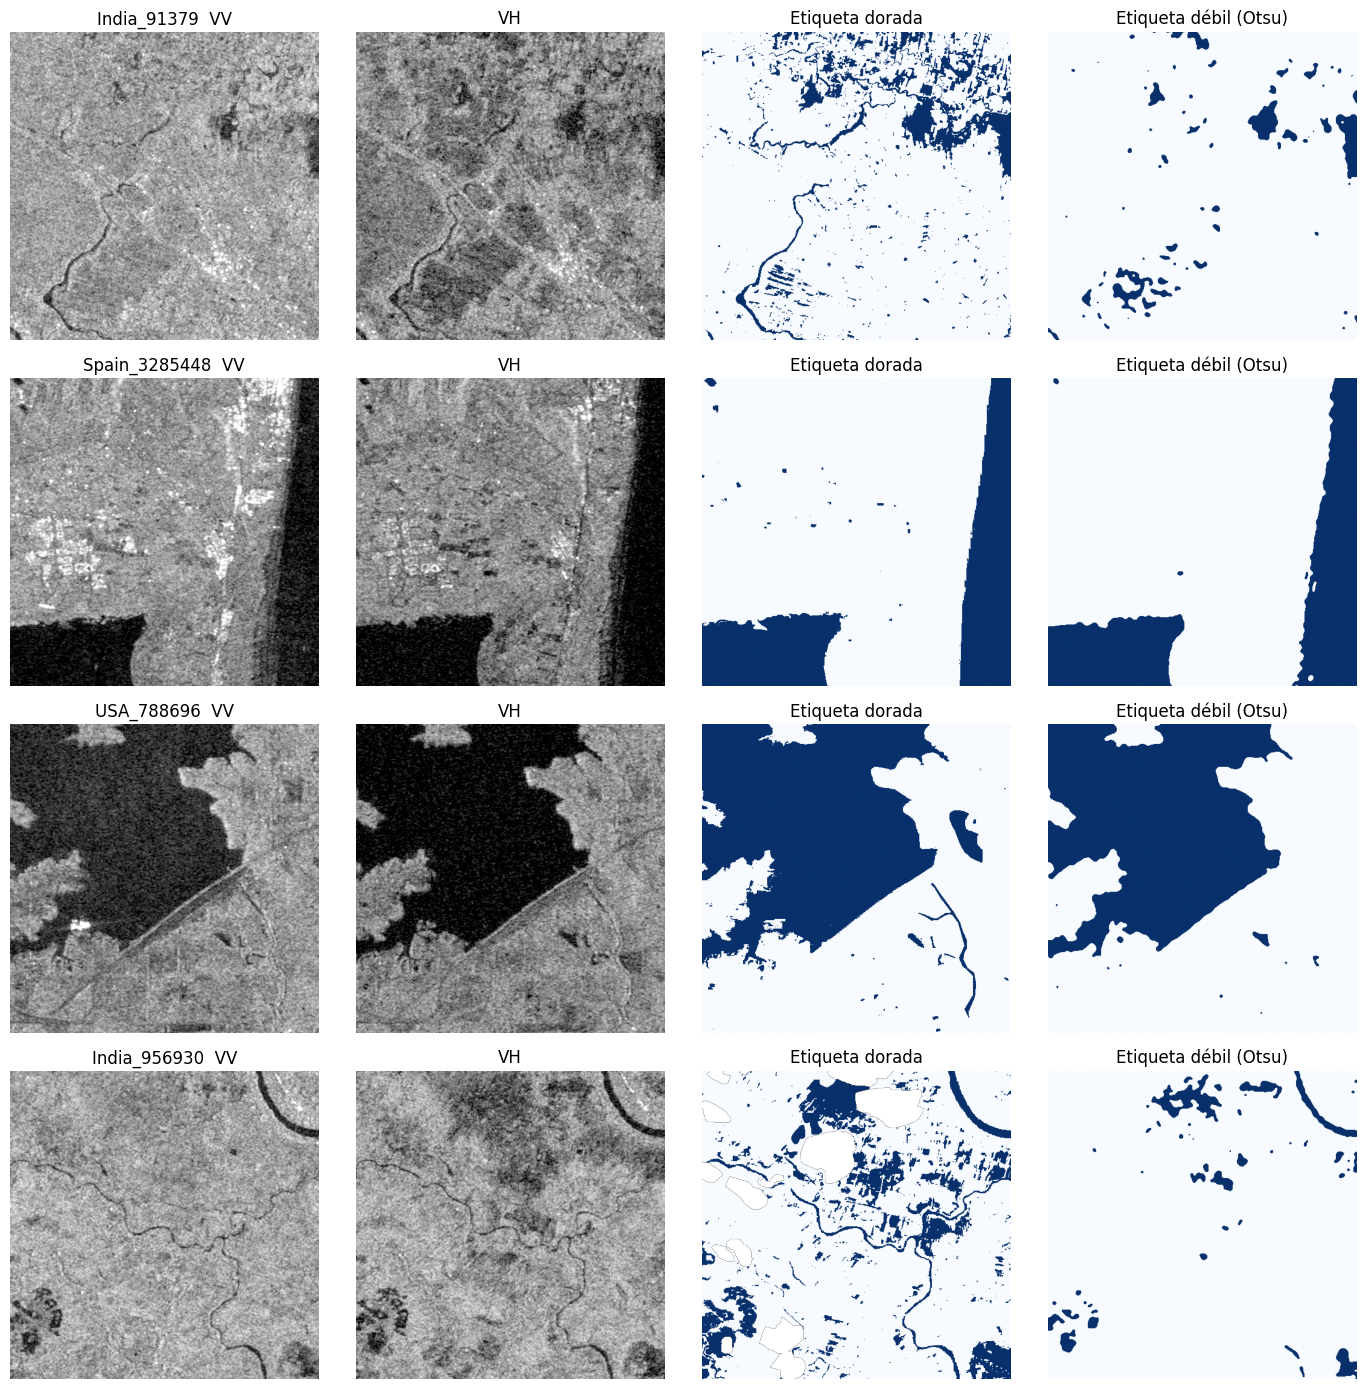

In [ ]:
def read(p, band=None):
    with rasterio.open(p) as d:
        return d.read() if band is None else d.read(band)
cands = []
for it in sp['train']:
    y = read(it['lab'], 1)
    f = (y == 1).mean()
    if 0.10 < f < 0.60: cands.append(it)
sel = random.Random(1).sample(cands, 4)
fig, ax = plt.subplots(4, 4, figsize=(14, 14))
for r, it in enumerate(sel):
    s1 = read(it['s1']); y = read(it['lab'], 1)
    otsu = read(it['lab'].replace('LabelHand', 'S1OtsuLabelHand').replace('_S1OtsuLabelHand.tif', '_S1OtsuLabelHand.tif'), 1)
    ax[r, 0].imshow(s1[0], cmap='gray', vmin=-25, vmax=0); ax[r, 0].set_title(f"{it['name'][:-11]}  VV")
    ax[r, 1].imshow(s1[1], cmap='gray', vmin=-30, vmax=-5); ax[r, 1].set_title('VH')
    ax[r, 2].imshow(np.ma.masked_less(y, 0), cmap='Blues', vmin=0, vmax=1); ax[r, 2].set_title('Etiqueta dorada')
    ax[r, 3].imshow(np.ma.masked_less(otsu, 0), cmap='Blues', vmin=0, vmax=1); ax[r, 3].set_title('Etiqueta débil (Otsu)')
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

## 5. ¿Cuán ruidosa es la etiqueta débil? (dorada vs. Otsu en los mismos chips)
Los autores publican la etiqueta Otsu también para los chips dorados (`S1OtsuLabelHand`). Comparándola con la dorada se **cuantifica el ruido** de la supervisión débil: este es el punto de partida empírico para decidir cómo combinar ambas fuentes en el notebook 02.

In [ ]:
def otsu_vs_gold(items):
    tp = fp = fn = tn = 0
    for it in items:
        y = read(it['lab'], 1)
        o = read(it['lab'].replace('LabelHand', 'S1OtsuLabelHand'), 1)
        v = (y >= 0) & (o >= 0)
        tp += ((o == 1) & (y == 1) & v).sum(); fp += ((o == 1) & (y == 0) & v).sum()
        fn += ((o == 0) & (y == 1) & v).sum(); tn += ((o == 0) & (y == 0) & v).sum()
    return counts_to_metrics(tp, fp, fn, tn)
res = {k: otsu_vs_gold(v) for k, v in sp.items()}
display(pd.DataFrame(res).T[['iou', 'omission', 'commission', 'precision', 'recall']].round(3))

,iou,omission,commission,precision,recall
train,0.451,0.314,0.431,0.569,0.686
val,0.506,0.284,0.367,0.633,0.716
test,0.546,0.267,0.319,0.681,0.733
bolivia,0.697,0.133,0.219,0.781,0.867


## 6. Retrodispersión por clase (¿qué separa agua de no agua?)
El agua en calma refleja especularmente la señal: **VV y VH muy bajos** (típicamente < −18 dB en VV y < −24 dB en VH). Las zonas urbanas y la vegetación inundada son los casos difíciles (retrodispersión *double-bounce* alta).

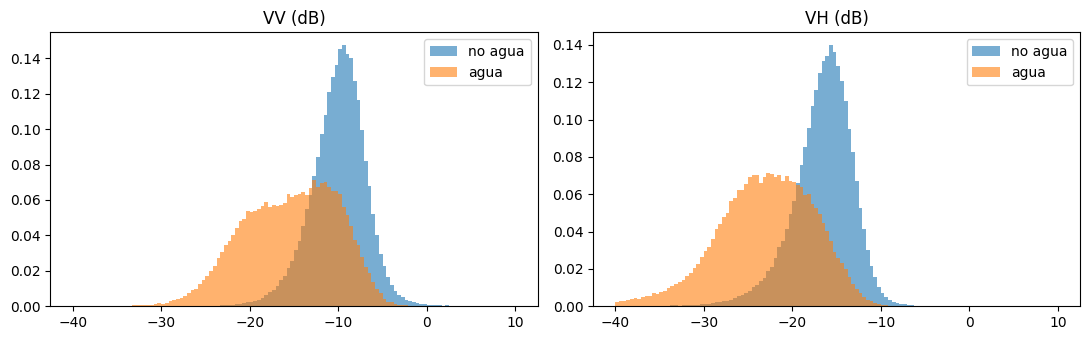

In [ ]:
rng = np.random.default_rng(0)
W, N = {'vv': [], 'vh': []}, {'vv': [], 'vh': []}
for it in rng.choice(sp['train'], 80, replace=False):
    s1 = read(it['s1']); y = read(it['lab'], 1)
    ok = np.isfinite(s1).all(0) & (y >= 0)
    for k, b in (('vv', 0), ('vh', 1)):
        W[k].append(rng.choice(s1[b][ok & (y == 1)], 2000) if (ok & (y == 1)).sum() > 2000 else s1[b][ok & (y == 1)])
        N[k].append(rng.choice(s1[b][ok & (y == 0)], 2000) if (ok & (y == 0)).sum() > 2000 else s1[b][ok & (y == 0)])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, k in zip(ax, ('vv', 'vh')):
    a.hist(np.concatenate(N[k]), 120, range=(-40, 10), alpha=.6, density=True, label='no agua')
    a.hist(np.concatenate(W[k]), 120, range=(-40, 10), alpha=.6, density=True, label='agua')
    a.set_title(k.upper() + ' (dB)'); a.legend()
plt.tight_layout(); plt.show()